# Step 6: Baselines (the bar a model must beat)

Two baselines, both fitted on the **train snapshot only**:
1. **mean**: everyone gets the train-average target.
2. **past_spend**: predicted future spend = `k * Monetary` (floored at 0). `k` is fitted on train as `sum(target) / sum(Monetary)`. `k` only sets the £ scale; the ranking is simply "sort by past spend".

Two ways to score them:
- **Train 5-fold CV:** fit on 4 folds, predict the held-out fold, pool the out-of-fold predictions. This is the protocol step 7 will use to choose between models.
- **Test:** fit on all train, score the later snapshot. Baselines have no tuned choices, so nothing is selected with this number.

Logic in `src/step6_baselines.py` and `src/metrics.py`.

## The three metrics (all in £, on the original scale)

| Metric | Question it answers |
|---|---|
| **R²** | How well do the predicted amounts fit? 0 = no better than predicting the average, 1 = perfect. |
| **MAE** | What is the typical error, in £? (Not dominated by a few huge customers.) |
| **Capture@20%** | If we contact the 20% of customers ranked highest, what share of all future money do they hold? Random ≈ 20%. |

Two reference lines that are *not* metrics: the **ceiling** (the best possible Capture@20%, from ranking by the true value) and the **"without the 10 biggest customers"** check (is the score driven by a handful of people?).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metrics import oracle_capture
from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF, TEST_CUTOFF
from step4_rfm import build_rfm
from step6_baselines import BASELINES, cv_predictions, score_table

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
ledger = load_ledger()
train, test = make_snapshot(ledger, TRAIN_CUTOFF), make_snapshot(ledger, TEST_CUTOFF)
Xtr, ytr = build_rfm(train), train.target
Xte, yte = build_rfm(test), test.target

## 1. Train, 5-fold cross-validation

In [2]:
cv = {name: cv_predictions(cls, Xtr, ytr) for name, cls in BASELINES.items()}
display(score_table(ytr.to_numpy(), cv).round(3))
print(f"ceiling (perfect ranking) Capture@20%: {oracle_capture(ytr.to_numpy()):.3f}")
print("Same, without the 10 biggest customers:")
display(score_table(ytr.to_numpy(), cv, without_top=10).round(3))

,R2,MAE,Capture@20%
mean,-0.000,944.129,0.170
past_spend,0.746,523.153,0.739


ceiling (perfect ranking) Capture@20%: 0.860
Same, without the 10 biggest customers:


,R2,MAE,Capture@20%
mean,-0.006,821.868,0.186
past_spend,0.549,471.154,0.686


## 2. Test (fit on all train, score the later snapshot)

In [3]:
fitted = {name: cls().fit(Xtr, ytr) for name, cls in BASELINES.items()}
print(f"fitted: mean = {fitted['mean'].mean_:.1f} | past_spend k = {fitted['past_spend'].k_:.3f}")
te = {name: m.predict(Xte) for name, m in fitted.items()}
display(score_table(yte.to_numpy(), te).round(3))
print(f"ceiling (perfect ranking) Capture@20%: {oracle_capture(yte.to_numpy()):.3f}")
print("Same, without the 10 biggest customers:")
display(score_table(yte.to_numpy(), te, without_top=10).round(3))

fitted: mean = 713.9 | past_spend k = 0.370


,R2,MAE,Capture@20%
mean,-0.002,1085.782,0.163
past_spend,0.707,613.477,0.739


ceiling (perfect ranking) Capture@20%: 0.832
Same, without the 10 biggest customers:


,R2,MAE,Capture@20%
mean,-0.000,886.964,0.193
past_spend,0.631,510.457,0.671


## 3. Seeing it: the cumulative gain curve (test)

Rank customers from best to worst by a score; the curve shows what share of all future money the top x% hold. Higher and further left is better. The dashed diagonal is random.

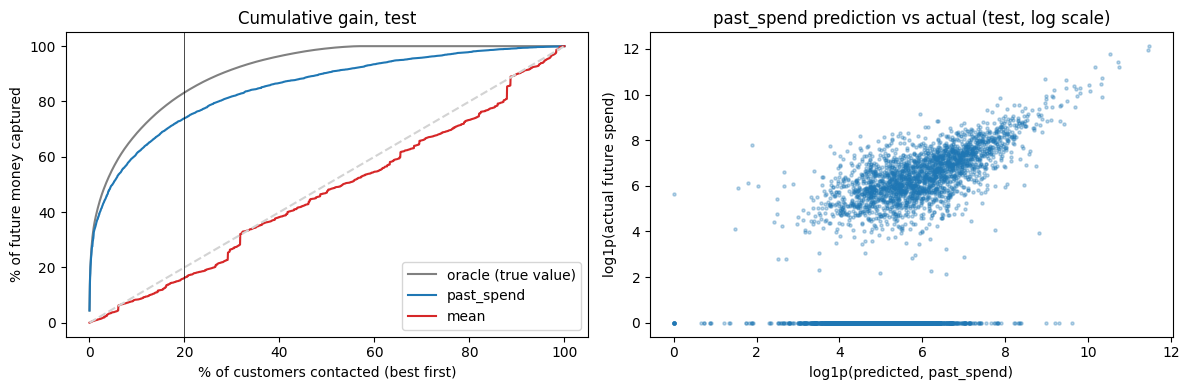

In [4]:
def gain_curve(y, score, seed=0):
    y, score = np.asarray(y, float), np.asarray(score, float)
    order = np.lexsort((np.random.default_rng(seed).random(len(y)), -score))
    return np.arange(1, len(y) + 1) / len(y) * 100, y[order].cumsum() / y.sum() * 100

y = yte.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for label, s, c in [("oracle (true value)", y, "gray"), ("past_spend", te["past_spend"], "tab:blue"), ("mean", te["mean"], "tab:red")]:
    x, g = gain_curve(y, s); ax.plot(x, g, label=label, color=c)
ax.plot([0, 100], [0, 100], "--", color="lightgray"); ax.axvline(20, color="k", lw=0.5)
ax.set_xlabel("% of customers contacted (best first)"); ax.set_ylabel("% of future money captured")
ax.set_title("Cumulative gain, test"); ax.legend()

ax = axes[1]
ax.scatter(np.log1p(te["past_spend"]), np.log1p(y), s=5, alpha=0.3)
ax.set_xlabel("log1p(predicted, past_spend)"); ax.set_ylabel("log1p(actual future spend)")
ax.set_title("past_spend prediction vs actual (test, log scale)")
plt.tight_layout()

The scatter's flat row at the bottom is the customers who spend nothing: past spend cannot tell them apart from similar customers who do come back. This is the weakness a two-stage (hurdle) model could address.

## What we learned

| | Train CV: mean | Train CV: past_spend | Test: mean | Test: past_spend |
|---|---|---|---|---|
| R² | 0.00 | **0.75** | 0.00 | **0.71** |
| MAE (£) | 944 | **523** | 1,086 | **613** |
| Capture@20% | 0.17 | **0.74** | 0.16 | **0.74** |

- **The mean is the floor:** R² ≈ 0 by construction. Its Capture@20% is chance (the 0.16-0.17 is one random tie-break draw).
- **Sorting by past spend is already strong:** it explains about 70-75% of the variation, is off by about £520-610 on a typical customer, and captures 74% of future money in the top 20%. The ceiling is 0.83-0.86, and random would be 0.20.
- **R² leans on a few people:** without the 10 biggest customers it falls from 0.75 to 0.55 (CV) and 0.71 to 0.63 (test). Capture and MAE hold up much better (capture 0.67-0.69).
- **The bar for step 7:** beat **R² ≈ 0.75 / 0.71, MAE ≈ 523 / 613, Capture@20% ≈ 0.74**. Capture has noise of roughly ±0.04 (measured earlier with a bootstrap), so differences smaller than that are not real.

**Next (step 7):** the four candidates, one at a time, starting with the simplest (a linear model on `log1p`), each compared with these baselines using 5-fold CV on train.